# Task 5: Account Security Monitoring (unsupervised anomaly detection)
Target `is_anomaly` (0 = normal, 1 = anomalous). **There are no labels and no train set**: only `test.csv`. Metric: **F3 = 10·P·R / (9P + R)**, so recall counts 9× more than precision.

**Pipeline:** load → EDA (what a period-4 jump looks like) → look for *separate crowds* instead of single outliers → link columns that point at the same accounts → one joint pattern that hides in three columns at once → F3 decision → write `task5` into the submission

**Idea in one line:** an honest tail thins out smoothly; a planted behaviour leaves a hole between itself and everybody else. The hole is the cut-off, so no threshold has to be guessed.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.sparse.csgraph import connected_components

import os, glob
# Data: this folder locally; on Kaggle the competition's 05_anomaly_detection folder (searched for if mounted elsewhere)
KAGGLE_DIR = '/kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main'
ON_KAGGLE = os.path.exists('/kaggle/input')
if ON_KAGGLE:
    DATA_DIR = f'{KAGGLE_DIR}/05_anomaly_detection'
    if not os.path.exists(f'{DATA_DIR}/test.csv'):
        DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/05_anomaly_detection/test.csv', recursive=True)[0])
else:
    DATA_DIR = '.'
OUT_DIR = '/kaggle/working' if ON_KAGGLE else '.'
print('data from:', os.path.abspath(DATA_DIR))
ID = 'player_id'
sns.set_theme(style='whitegrid')
df = pd.read_csv(f'{DATA_DIR}/test.csv'); N = len(df)
FEATS = [c for c in df.columns if c != ID]
BASE = sorted({c.rsplit('_', 1)[0] for c in FEATS if c[-2:] in ('_1', '_2', '_3', '_4')})   # 29 measures x 4 periods
FLAGS = ['password_changed', 'vpn_usage', 'suspicious_login_time', 'mass_item_sale']
print(df.shape, '|', len(BASE), 'time-series measures x 4 periods +', len(FEATS) - 4 * len(BASE), 'static columns')
print('missing share per column (median):', round(float(df[FEATS].isna().mean().median()), 3))

data from: /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/05_anomaly_detection
(25889, 123) | 29 time-series measures x 4 periods + 6 static columns
missing share per column (median): 0.049


## 1. EDA: what a period-4 jump looks like

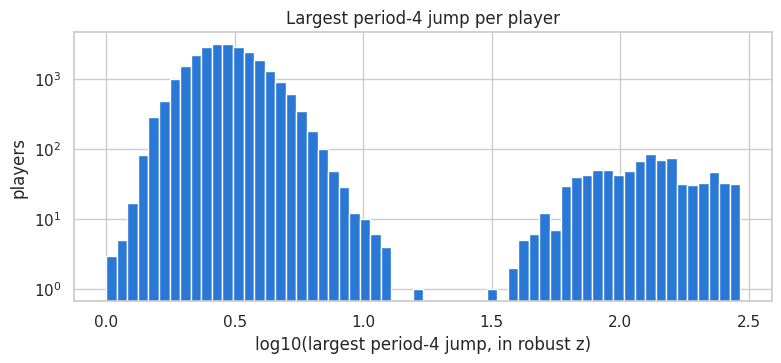

Security flags by jump size (flags were not used to build the score):


,jump z,players,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,0-6,24655,0.049,0.152,0.050,0.021
1,6-12,403,0.059,0.142,0.057,0.026
2,12-inf,831,0.398,0.378,0.058,0.276


In [2]:
# last period vs the player's own earlier mean, robust z-scored across players (MAD, so the odd accounts do not hide themselves)
Z = pd.DataFrame(index=df.index)
for b in BASE:
    M = df[[f'{b}_{i}' for i in (1, 2, 3, 4)]].values
    dev = M[:, 3] - np.nanmean(M[:, :3], axis=1)
    c = np.nanmedian(dev)
    Z[b] = np.abs(dev - c) / (np.nanmedian(np.abs(dev - c)) * 1.4826 + 1e-9)
jump = Z.max(axis=1)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(np.log10(jump.clip(lower=1)), bins=60, color='#2a78d6')
ax.set(xlabel='log10(largest period-4 jump, in robust z)', ylabel='players', yscale='log', title='Largest period-4 jump per player')
plt.show()
bands = [(0, 6), (6, 12), (12, np.inf)]
print('Security flags by jump size (flags were not used to build the score):')
pd.DataFrame([{'jump z': f'{lo}-{hi}', 'players': int(((jump > lo) & (jump <= hi)).sum()),
               **{f: round(df.loc[(jump > lo) & (jump <= hi), f].mean(), 3) for f in FLAGS}} for lo, hi in bands])

**What this shows.** A group of about 3% of players jump far outside normal in the last period (login location moves ~34°, skill rating doubles, currency transfers multiply) and their security flags are 2.5-13× higher than everyone else's (password change 40% vs 5%, mass item sale 28% vs 2%). That is clearly anomalous behaviour, but it is **only one kind** of odd account. The brief also describes bots, farm accounts and resellers, whose behaviour does *not* change between periods, so a "last period vs earlier" score cannot see them. The next section looks for odd accounts without assuming how they differ.

## 2. Separate crowds instead of single outliers
For every column and each end of its distribution, look at the gaps that leave a small crowd beyond them (at least 20 accounts, at most 3% of all). A gap is **suspicious when the dense side would have put many accounts inside it**: `hole_score` = gap width ÷ the average spacing between the 200 accounts just before it (how many accounts the gap would hold at that density). With `hole_score ≥ 50` the crowd beyond the gap is separate from the rest. The innermost such gap is used, because it keeps the most members, which is what F3 wants.

In [3]:
NEIGHBOURS, HOLE_SCORE, MIN_SIZE, MAX_SHARE = 200, 50, 20, .03

def innermost_hole(s):
    # s is sorted so that the tail of interest is at the end; returns the index just before the hole, or None
    n = len(s)
    i = np.arange(max(n - 1 - int(MAX_SHARE * n), NEIGHBOURS), n - MIN_SIZE)       # accounts beyond the gap: n-1-i
    span = s[i] - s[i - NEIGHBOURS + 1]                                              # width covered by the 200 accounts before it
    width = s[i + 1] - s[i]
    with np.errstate(divide='ignore', invalid='ignore'):
        score = NEIGHBOURS * width / span
    hit = np.flatnonzero((span > 0) & (score >= HOLE_SCORE))
    return int(i[hit[0]]) if hit.size else None

def separate_crowds(frame):
    out = []
    for col in FEATS:
        v = frame[col].to_numpy(float); have = np.flatnonzero(~np.isnan(v)); o = np.argsort(v[have], kind='stable')
        vals, rows = v[have][o], have[o]
        for side, (s, r) in {'high': (vals, rows), 'low': (-vals[::-1], rows[::-1])}.items():
            cut = innermost_hole(s)
            if cut is not None:
                m = np.zeros(len(frame), bool); m[r[cut + 1:]] = True
                out.append((col, side, m))
    return out

crowds = separate_crowds(df)
print(f'{len(crowds)} separate crowds found across {len(FEATS)} columns')
pd.DataFrame([(c, s, int(m.sum())) for c, s, m in crowds], columns=['column', 'end', 'accounts']).head(12)

36 separate crowds found across 122 columns


,column,end,accounts
0,login_count_3,low,30
1,login_lat_3,high,22
2,login_lat_4,high,137
3,login_lon_4,high,51
4,location_changes_4,high,493
5,ip_hash_entropy_1,low,198
6,ip_hash_entropy_2,low,199
7,ip_hash_entropy_3,low,197
8,ip_hash_entropy_4,low,194
9,login_time_variance_1,low,196


## 3. Link the columns that point at the same accounts
One planted behaviour shows up in several columns (a bot has low IP entropy *and* regular login times *and* constant session length). Two crowds that share at least half of the smaller one's accounts are treated as the same **behaviour group**.

In [4]:
def link_columns(found, shared=.5):
    A = np.array([m for _, _, m in found]).astype(int)
    size = A.sum(1)
    adj = (A @ A.T) >= shared * np.minimum.outer(size, size)
    _, label = connected_components(adj, directed=False)
    return label

def name_group(cols):
    names = {'location_changes': 'travel / location jumps', 'login_lat': 'travel / location jumps', 'skill_rating': 'skill jump + friend removals',
             'friend_removes': 'skill jump + friend removals', 'activity_level': 'barely active', 'communication_frequency': 'silent (no chat)',
             'behavior_stability': 'unstable behaviour', 'ip_hash_entropy': 'one-IP routine (bot-like)'}
    return next((v for c in cols for k, v in names.items() if c.startswith(k)), cols[0])

label = link_columns(crowds)
groups = {}
for g in np.unique(label):
    idx = np.flatnonzero(label == g)
    mask = np.logical_or.reduce([crowds[i][2] for i in idx])
    groups[name_group([crowds[i][0] for i in idx])] = mask
in_group = np.logical_or.reduce(list(groups.values()))

rows = [{'behaviour group': k, 'accounts': int(m.sum()), **{f: round(df.loc[m, f].mean(), 3) for f in FLAGS}} for k, m in groups.items()]
rows.append({'behaviour group': 'everyone else', 'accounts': int((~in_group).sum()), **{f: round(df.loc[~in_group, f].mean(), 3) for f in FLAGS}})
print(f'{len(groups)} behaviour groups, {in_group.sum()} accounts ({in_group.mean():.2%})')
pd.DataFrame(rows).sort_values('accounts', ascending=False).reset_index(drop=True)

6 behaviour groups, 1812 accounts (7.00%)


,behaviour group,accounts,password_changed,vpn_usage,suspicious_login_time,mass_item_sale
0,everyone else,24077,0.049,0.153,0.051,0.021
1,travel / location jumps,517,0.605,0.515,0.068,0.427
2,skill jump + friend removals,313,0.058,0.150,0.037,0.024
3,barely active,265,0.057,0.116,0.044,0.012
4,silent (no chat),263,0.057,0.091,0.055,0.020
5,unstable behaviour,247,0.059,0.142,0.034,0.030
6,one-IP routine (bot-like),207,0.041,0.190,0.046,0.010


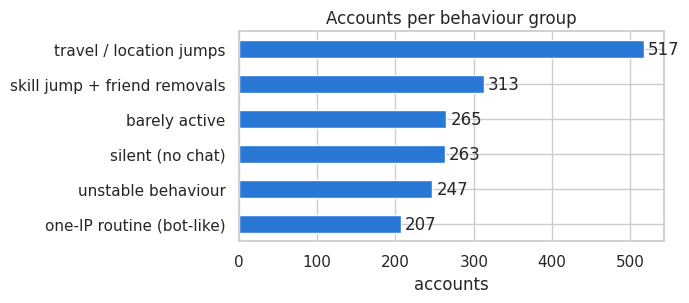

In [5]:
sizes = pd.Series(groups).map(np.sum).astype(int).sort_values()
ax = sizes.plot.barh(figsize=(7, 3.2), color='#2a78d6'); ax.set(title='Accounts per behaviour group', xlabel='accounts')
for row, count in enumerate(sizes): ax.annotate(f'{count:,}', (count, row), xytext=(3, 0), textcoords='offset points', va='center')
plt.tight_layout(); plt.show()

**Reading it.** Six groups, 7% of all accounts. The security flags were never used to find them, and they confirm only **one** group: in the travel / location group 61% changed their password, 52% use a VPN and 43% sold items in bulk (everyone else: 5%, 15%, 2%). In the other five groups the flags sit at the normal rate. 827 of the 838 period-4 jumpers from section 1 are inside the six groups (517 in the travel group, 310 in the skill-jump group), so the groups contain the earlier finding plus four kinds of account a "last period vs earlier" score cannot see.

**Caveat on the skill-jump group:** its flags are at the normal rate, which fits account sharing or boosting but also fits players who simply improved (the brief warns that simple thresholds flag those). Without labels we cannot tell. It is kept because the group is clearly separate from the crowd and F3 forgives a few extra flags far more than missed ones. A whole-table ranking (Isolation Forest + PCA error, top 12.5%) found only 1,241 of the 1,812 group accounts.

## 4. One pattern that hides in two columns at once
Some accounts are odd only in combination: two columns are each in a normal range, but both are high at once. No single column then shows a gap. For two independent features, every cell of a 20×20 grid of their rank percentiles should hold n/400 accounts. We look at the spread of KDA and the spread of accuracy over the four periods (outside the groups above).

24077 accounts, expected per cell 60.2; fullest cell 222 (top-right corner: 222)


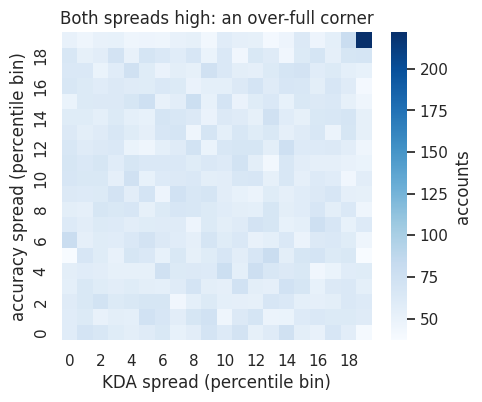

In [6]:
mean_over_periods = lambda b: df[[f'{b}_{i}' for i in (1, 2, 3, 4)]].mean(axis=1)
pool = np.flatnonzero(~in_group & mean_over_periods('accuracy_std').notna().values & mean_over_periods('kda_std').notna().values)
n = len(pool)
pct = lambda b: pd.Series(mean_over_periods(b).values[pool]).rank(pct=True).values
pa, pk = pct('accuracy_std'), pct('kda_std')
grid = np.zeros((20, 20), int)
np.add.at(grid, (np.minimum((pa * 20).astype(int), 19), np.minimum((pk * 20).astype(int), 19)), 1)
print(f'{n} accounts, expected per cell {n / 400:.1f}; fullest cell {grid.max()} (top-right corner: {grid[19, 19]})')
fig, ax = plt.subplots(figsize=(5, 4)); sns.heatmap(grid, cmap='Blues', ax=ax, cbar_kws={'label': 'accounts'})
ax.set(xlabel='KDA spread (percentile bin)', ylabel='accuracy spread (percentile bin)', title='Both spreads high: an over-full corner'); ax.invert_yaxis(); plt.show()

**Cut-off for this group.** Each account gets min(percentile of KDA spread, percentile of accuracy spread), which is large only if both spreads are large. If the two spreads were independent, the number of accounts above percentile q would be n·(1−q)². So for the top-k accounts, `k − n·(1−q)²` estimates how many are genuinely in the group. Pick the k that maximises the expected F3 when the six groups above count as true anomalies.

In [7]:
score = np.minimum(pa, pk); order = np.argsort(-score); q = score[order]
ks = np.arange(20, 1500)
members = np.maximum(ks - n * (1 - q[ks - 1]) ** 2, 0)       # estimated true members among the top k
G = members.max()
TP, flagged = in_group.sum() + members, in_group.sum() + ks
P, R = TP / flagged, TP / (in_group.sum() + G)
K = int(ks[np.argmax(10 * P * R / (9 * P + R))])
joint = np.zeros(N, bool); joint[pool[order[:K]]] = True
print(f'estimated group size {G:.0f}; best cut-off k = {K} (about {members[K - 20]:.0f} true members, precision {members[K - 20] / K:.2f})')

estimated group size 200; best cut-off k = 339 (about 194 true members, precision 0.57)


**Is the group odd in a third column too?** If the group was planted with more than two columns, its members are shifted in that column as well, while normal accounts in the corner are not (the columns are independent). For every other all-period column we compare its percentile inside the provisional group with the pool (mean percentile 0.5 if unrelated; z-score against the uniform spread, Bonferroni bound over all columns tested). Exactly one column passes: `performance_stability`, and the group sits in a narrow band of it. The cut-off is then redone inside that band: the band is the run of histogram bins where the both-spreads-high corner holds more than twice its expected count, widened by half a bin on each side. Inside the band the same `k − n·(1−q)²` estimate and expected-F3 choice are used, with n = accounts in the band.

third-column shift z (Bonferroni bound 3.11):
performance_stability    16.0
guild_changes            -1.4
ip_hash_entropy           1.3
session_duration_std     -1.2
friend_adds              -1.2
performance_stability band [0.856, 0.942] (5889 accounts): estimated group size 258; cut-off k = 322 (about 240 true members, precision 0.75); two-column version: 194 members at precision 0.57; overlap 253


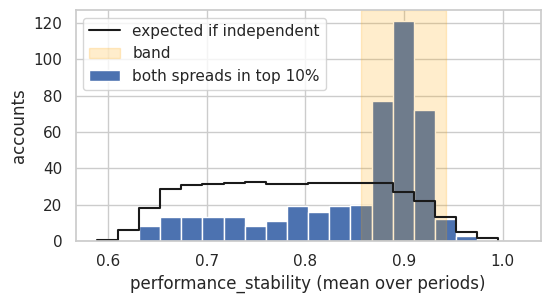

In [8]:
from scipy.stats import norm
prov = order[:K]                                            # provisional group, positions in pool
others = sorted({c[:-2] for c in df.columns if c[-2:] == '_4'} - {'accuracy_std', 'kda_std'})
shift = {}
for b in others:
    r = pd.Series(mean_over_periods(b).values[pool]).rank(pct=True).values[prov]; r = r[~np.isnan(r)]
    shift[b] = (r.mean() - .5) / np.sqrt(1 / 12 / len(r))
shift = pd.Series(shift).sort_values(key=abs, ascending=False); bound = norm.ppf(1 - .025 / len(shift))
print(f'third-column shift z (Bonferroni bound {bound:.2f}):'); print(shift.head(5).round(1).to_string())
third = shift.index[0]; assert abs(shift.iloc[0]) > bound and abs(shift.iloc[1]) < bound, 'expected exactly one clear third column'

v = mean_over_periods(third).values[pool]; corner = (pa >= .9) & (pk >= .9)
edges = np.linspace(np.nanmin(v), np.nanmax(v), 21); w = edges[1] - edges[0]
h, _ = np.histogram(v[corner], edges); h0, _ = np.histogram(v[~corner], edges)
excess = np.flatnonzero(h > 2 * h0 * corner.sum() / (~corner).sum())
lo, hi = edges[excess.min()] - w / 2, edges[excess.max() + 1] + w / 2
band = np.flatnonzero((v >= lo) & (v <= hi)); nb = len(band)
score_b = np.minimum(pa[band], pk[band]); order_b = np.argsort(-score_b); qb = score_b[order_b]
members_b = np.maximum(ks - nb * (1 - qb[ks - 1]) ** 2, 0); Gb = members_b.max()
TPb = in_group.sum() + members_b; Pb, Rb = TPb / (in_group.sum() + ks), TPb / (in_group.sum() + Gb)
Kb = int(ks[np.argmax(10 * Pb * Rb / (9 * Pb + Rb))])
joint2 = joint; joint = np.zeros(N, bool); joint[pool[band[order_b[:Kb]]]] = True
print(f'{third} band [{lo:.3f}, {hi:.3f}] ({nb} accounts): estimated group size {Gb:.0f}; cut-off k = {Kb} '
      f'(about {members_b[Kb - 20]:.0f} true members, precision {members_b[Kb - 20] / Kb:.2f}); '
      f'two-column version: {members[K - 20]:.0f} members at precision {members[K - 20] / K:.2f}; overlap {(joint & joint2).sum()}')
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(edges[:-1], h, w, align='edge', label='both spreads in top 10%')
ax.step(edges[:-1], h0 * corner.sum() / (~corner).sum(), where='post', color='k', label='expected if independent')
ax.axvspan(lo, hi, color='orange', alpha=.2, label='band'); ax.set(xlabel=f'{third} (mean over periods)', ylabel='accounts'); ax.legend(); plt.show()

## 5. Decision and submission
Flag every behaviour group and the joint-pattern group. F3 charges a missed anomaly about 9× what it charges a false alarm, so groups that are clearly separate are flagged in full. Writes `task5` into `../submission.csv` and keeps the other columns. If that file doesn't exist yet, it starts from `sample_submission.csv`.

In [9]:
flag = (in_group | joint).astype(int)
print(f'flagged {flag.sum()} accounts ({flag.mean():.2%}) = behaviour groups {in_group.sum()} + joint pattern {joint.sum()}')

# Full submission: locally ../submission.csv; on Kaggle our best submission.csv if it is attached as a dataset,
# otherwise the competition's sample_submission.csv (then only this task's column is real)
if ON_KAGGLE:
    full = glob.glob('/kaggle/input/**/submission.csv', recursive=True)
    SUB = full[0] if full else glob.glob('/kaggle/input/**/sample_submission.csv', recursive=True)[0]
    OUT = f'{OUT_DIR}/submission.csv'
else:
    SUB = '../submission.csv' if os.path.exists('../submission.csv') else '../sample_submission.csv'
    OUT = '../submission.csv'
sub = pd.read_csv(SUB)
assert len(sub) == len(df), 'row count mismatch'
pd.DataFrame({'id': sub['id'], 'task5': flag}).to_csv(f'{OUT_DIR}/submission_task5.csv', index=False)
sub['task5'] = flag   # assumes row i of the submission = row i of test.csv
sub.to_csv(OUT, index=False)
print(f'updated {OUT} from {SUB}'); sub.head()

flagged 2134 accounts (8.24%) = behaviour groups 1812 + joint pattern 322
updated /kaggle/working/submission.csv from /kaggle/input/competitions/player-intelligence-system-cpe-342-ml/cpe342-kaggle-main/sample_submission.csv


,id,task1,task2,task3,task4,task5
0,ANS00001,1.0,2.0,2983.20,0.0,1
1,ANS00002,0.0,1.0,529.00,1.0,0
2,ANS00003,1.0,3.0,15682.45,2.0,1
3,ANS00004,0.0,2.0,7200.00,0.0,0
4,ANS00005,NaN,NaN,NaN,NaN,0


### Key insights
1. **Planted behaviours form separate crowds.** Six behaviours each show up as a small crowd cut off from everyone else by an empty stretch of values; that empty stretch is the cut-off, so no threshold has to be picked.
2. **A "last period vs earlier" score only sees one of them.** Travel and skill jumps are visible that way. Bots, silent or barely-active accounts and very unstable accounts are odd in every period, and one more group is odd only in three columns together (KDA spread, accuracy spread and a narrow band of performance stability).
3. **The security flags confirm only the travel group** (not used to build it), and are at the normal rate in the other five. Those groups are real separate crowds in the data, but nothing independent tells us they are anomalies; the skill-jump group could be genuine improvers.
4. **A whole-table detector misses a quarter of the groups** (1,241 of 1,812 inside its top 12.5%), because each planted behaviour differs in only a few of the 122 columns.
5. The flag count (about 8%) is an outcome of the data, not a setting. It is an estimate: there are no labels to check it against.